
Read Data and its properties

In [1]:
import pandas as pd

df = pd.read_csv('SpotifyFeatures.csv')

# # Preview the dataset
print(df.head())
print(df.info())
print(df['genre'].value_counts())  # Check class balance

print(df.isnull().sum())  # Null check
print(df.dtypes)          # Data types

df = df.dropna()  

   genre        artist_name                        track_name  \
0  Movie     Henri Salvador       C'est beau de faire un Show   
1  Movie  Martin & les fées  Perdu d'avance (par Gad Elmaleh)   
2  Movie    Joseph Williams    Don't Let Me Be Lonely Tonight   
3  Movie     Henri Salvador    Dis-moi Monsieur Gordon Cooper   
4  Movie       Fabien Nataf                         Ouverture   

                 track_id  popularity  acousticness  danceability  \
0  0BRjO6ga9RKCKjfDqeFgWV           0         0.611         0.389   
1  0BjC1NfoEOOusryehmNudP           1         0.246         0.590   
2  0CoSDzoNIKCRs124s9uTVy           3         0.952         0.663   
3  0Gc6TVm52BwZD07Ki6tIvf           0         0.703         0.240   
4  0IuslXpMROHdEPvSl1fTQK           4         0.950         0.331   

   duration_ms  energy  instrumentalness key  liveness  loudness   mode  \
0        99373   0.910             0.000  C#    0.3460    -1.828  Major   
1       137373   0.737             0.000  F#

Plot HeatMap of Features

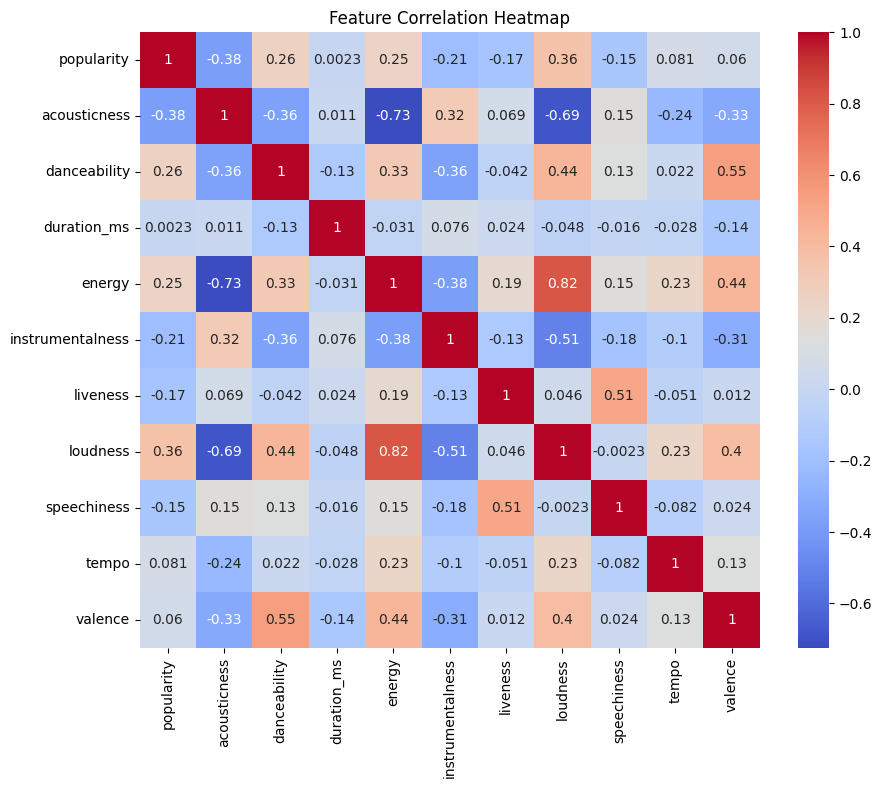

In [2]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])

import seaborn as sns
import matplotlib.pyplot as plt

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

Plot BoxPlot of Features

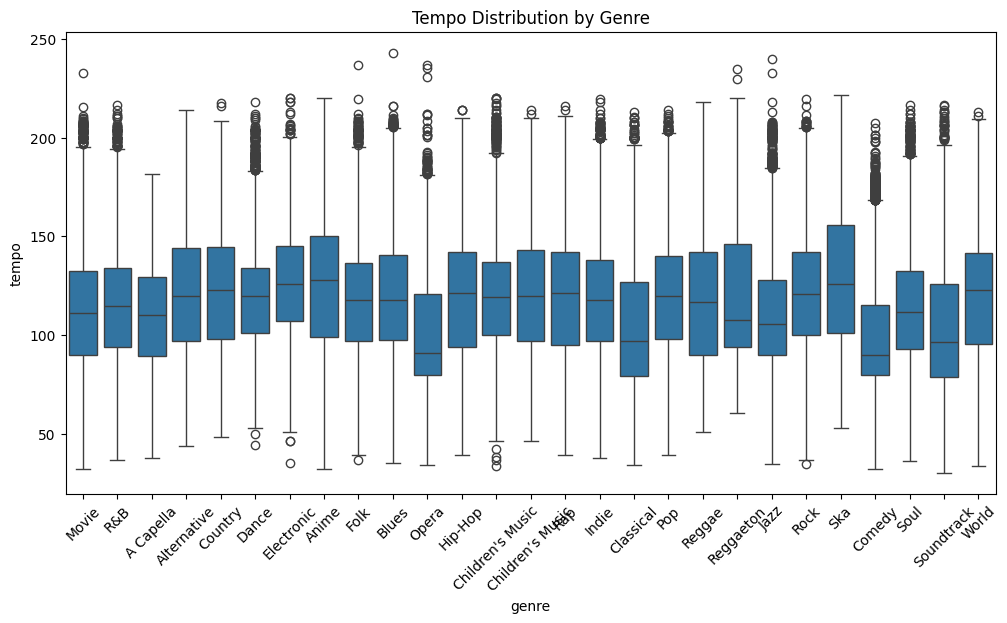

In [3]:
# Boxplot for a feature across genres
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='genre', y='tempo')
plt.xticks(rotation=45)
plt.title('Tempo Distribution by Genre')
plt.show()

Encode Labels and seperate X and Y

In [4]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['genre_encoded'] = le.fit_transform(df['genre'])

from sklearn.preprocessing import StandardScaler

features = ['acousticness', 'danceability', 'energy', 'instrumentalness', 'tempo', 'loudness']
X = df[features]
y = df['genre_encoded']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Split train and test Data Use Random forest to train machine

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

# Train model
clf = RandomForestClassifier(n_estimators=100, random_state=42)

clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)


Print Metrices

In [6]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy: 0.24359222258029864
Confusion Matrix:
[[   0    0    0    1    0    0    0    1    1    0    0    1    0    1
     1    4   10    0    0    0    0    2    0    0    0    0    2]
 [   0   31   35   54    4  711    1    2   48   63   42   58   57  108
    16    5    2   34  114   79   19   21  177   79   48    3   42]
 [   0   41  460   60   19   28   88    6  120   58  128   34    9   20
    63   30   36   18   18    5   17   24   17  165   20  229   74]
 [   0   45   49  349   38   32   10   31   90   26   89  165   13   40
   149   54   18   17   21   11   36   30  101  110  177   17   87]
 [   0    2   14   37  422    1   15   22   40   13   29   57   33   11
    56   81   19    9   14   19   54   60    5    5   33   15   15]
 [   0  700   29   39    3   10    2    2   35   45   19   53   70  157
    15    4    1   48  122   62   13    8  255   54   54    1   70]
 [   0    8   44   19    7    6  905    5    3    1    8   14    0    2
    42   37  299    0    1    0    3    

c:\Users\akraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                  precision    recall  f1-score   support

       A Capella       0.00      0.00      0.00        24
     Alternative       0.02      0.02      0.02      1853
           Anime       0.32      0.26      0.29      1787
           Blues       0.18      0.19      0.19      1805
Children's Music       0.44      0.39      0.41      1081
Children’s Music       0.01      0.01      0.01      1871
       Classical       0.48      0.49      0.48      1851
          Comedy       0.85      0.90      0.88      1936
         Country       0.18      0.20      0.19      1733
           Dance       0.06      0.06      0.06      1740
      Electronic       0.39      0.44      0.42      1876
            Folk       0.08      0.08      0.08      1860
         Hip-Hop       0.04      0.05      0.05      1859
           Indie       0.01      0.01      0.01      1909
            Jazz       0.22      0.21      0.22      1888
           Movie       0.27      0.22      0.24      1561
           Op

c:\Users\akraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\akraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Logistic Regression For Machine Learning

In [7]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000, multi_class='multinomial', solver='lbfgs')
clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

c:\Users\akraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.23366634439789452
Confusion Matrix:
[[   0    0    0    0    3    0    0    0    0    0    0    3    0    0
     0    2   13    0    0    0    0    2    0    0    1    0    0]
 [   0    8   71   20   37  217    1   21   21   57   92   52   73   40
    21   40    7   60   99   60   55  115   24  544   37    7   74]
 [   0    6  105    2   18  132   79    8   15   92  133   26    2   27
    97   20   47   60   27   12    5   95    7  509    7  211   45]
 [   0    2  126   81   76  107    7   71   25   20   62   86   28   34
    58  133   25   44   67   28   55   67   41  332   68    8  154]
 [   0    0    4   14  350    3   11   33   11    0   34   40   74    6
   114   68   31   13   37   17   52  100    6    9   41    6    7]
 [   0   11   50   24   26  228    0   30   18   60   85   75   62   34
    22   44    3   63   95   61   45  117   41  569   23    5   80]
 [   0    0   28    0    5    9  733   22    1    0   16    9    0    1
    53   51  369    1    1    1    0    

c:\Users\akraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\akraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\akraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

Knn for Traning and Prediction

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Train KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# Predict
y_pred_knn = knn_model.predict(X_test)

# Evaluate
print("🔹 KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("🔹 KNN Classification Report:")
print(classification_report(y_test, y_pred_knn, target_names=le.classes_))


🔹 KNN Accuracy: 0.20197658180255668
🔹 KNN Classification Report:
                  precision    recall  f1-score   support

       A Capella       0.00      0.00      0.00        24
     Alternative       0.04      0.12      0.06      1853
           Anime       0.16      0.26      0.20      1787
           Blues       0.10      0.17      0.12      1805
Children's Music       0.20      0.29      0.24      1081
Children’s Music       0.02      0.02      0.02      1871
       Classical       0.38      0.48      0.42      1851
          Comedy       0.74      0.86      0.79      1936
         Country       0.11      0.15      0.12      1733
           Dance       0.07      0.09      0.08      1740
      Electronic       0.32      0.31      0.31      1876
            Folk       0.09      0.08      0.08      1860
         Hip-Hop       0.08      0.09      0.09      1859
           Indie       0.04      0.02      0.02      1909
            Jazz       0.23      0.16      0.19      1888
      

GradientBoostingClassifier for Traning and Prediction

In [9]:
from sklearn.ensemble import GradientBoostingClassifier

# Train Gradient Boosting
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb_model.fit(X_train, y_train)

# Predict
y_pred_gb = gb_model.predict(X_test)

# Evaluate
print("🔹 Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print("🔹 Gradient Boosting Classification Report:")
print(classification_report(y_test, y_pred_gb, target_names=le.classes_))


🔹 Gradient Boosting Accuracy: 0.2811472768288753
🔹 Gradient Boosting Classification Report:
                  precision    recall  f1-score   support

       A Capella       0.00      0.00      0.00        24
     Alternative       0.14      0.05      0.08      1853
           Anime       0.28      0.23      0.25      1787
           Blues       0.18      0.21      0.19      1805
Children's Music       0.35      0.35      0.35      1081
Children’s Music       0.12      0.07      0.09      1871
       Classical       0.48      0.52      0.50      1851
          Comedy       0.77      0.89      0.83      1936
         Country       0.15      0.27      0.19      1733
           Dance       0.16      0.17      0.17      1740
      Electronic       0.35      0.47      0.40      1876
            Folk       0.17      0.24      0.20      1860
         Hip-Hop       0.18      0.19      0.18      1859
           Indie       0.10      0.03      0.05      1909
            Jazz       0.26      0.25